Top 20% customers contribute: 74.59 % of revenue


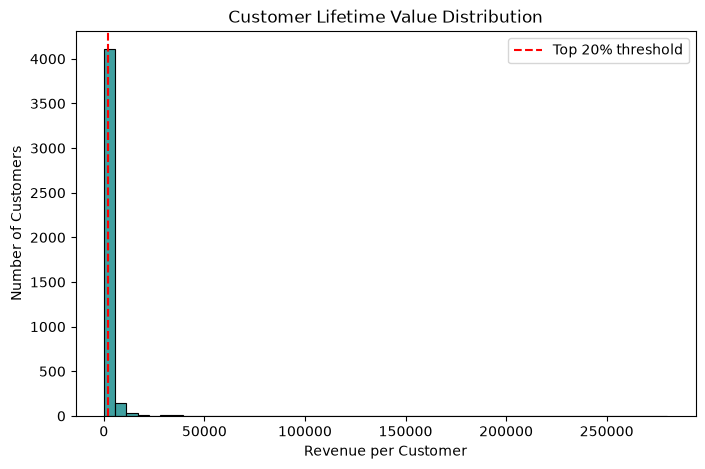

Inactive customers (>90 days): 32.22 %


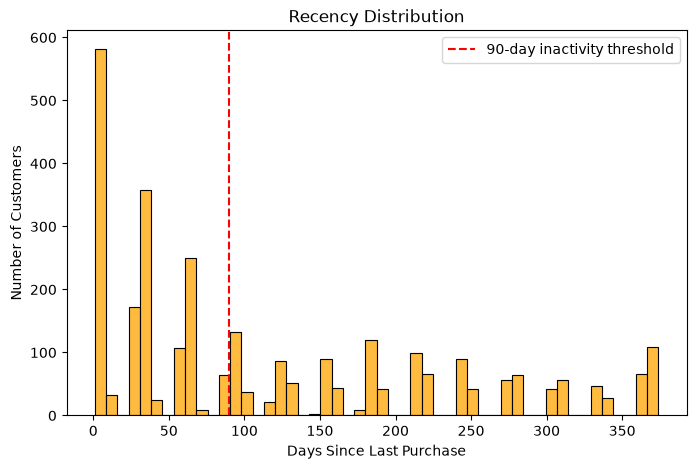

Avg purchases Loyal: 163.94 vs Casual: 18.03


C:\Users\SONIA\AppData\Local\Temp\ipykernel_14036\646350890.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Loyal','Casual'], y=[avg_freq_loyal, avg_freq_casual], palette='viridis')


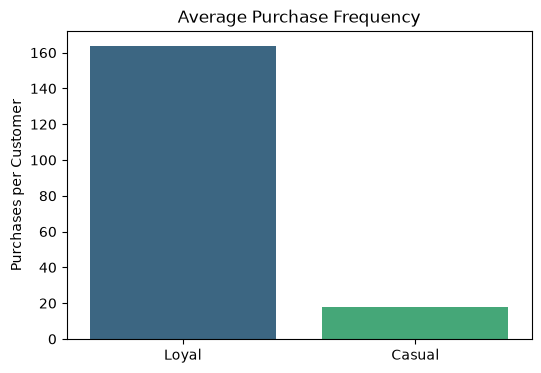

Champions revenue share: 79.13 %
At-Risk revenue share: 2.18 %


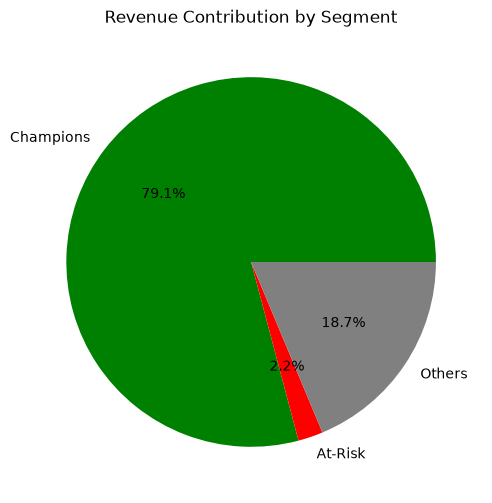

Overall AOV: 480.76


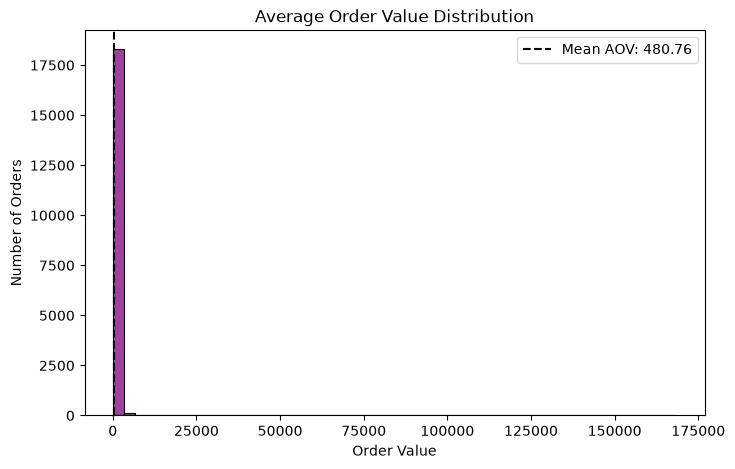

In [2]:
# --- Setup ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

# --- Load dataset ---
df = pd.read_csv(r"C:\Users\SONIA\Documents\AI_Project\AI_Retail_Data.csv", encoding='unicode_escape')

# --- Data Cleaning ---
df = df.dropna(subset=['CustomerID'])
df = df[df['Quantity'] > 0]
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
df['Total'] = df['Quantity'] * df['UnitPrice']

# Snapshot date for recency
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# --- KPI 1: Customer Lifetime Value (CLV proxy = Monetary) ---
clv = df.groupby('CustomerID')['Total'].sum().sort_values(ascending=False)
top_20pct_customers = clv.head(int(len(clv)*0.2))

print("Top 20% customers contribute:", round(top_20pct_customers.sum()/clv.sum()*100,2), "% of revenue")

# Visualization
plt.figure(figsize=(8,5))
sns.histplot(clv, bins=50, color='teal')
plt.axvline(top_20pct_customers.min(), color='red', linestyle='--', label='Top 20% threshold')
plt.title("Customer Lifetime Value Distribution")
plt.xlabel("Revenue per Customer")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

# --- KPI 2: Recency Distribution ---
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'count',
    'Total': 'sum'
})
rfm.rename(columns={'InvoiceDate':'Recency','InvoiceNo':'Frequency','Total':'Monetary'}, inplace=True)

inactive_customers = (rfm['Recency'] > 90).mean()*100
print("Inactive customers (>90 days):", round(inactive_customers,2), "%")

# Visualization
plt.figure(figsize=(8,5))
sns.histplot(rfm['Recency'], bins=50, color='orange')
plt.axvline(90, color='red', linestyle='--', label='90-day inactivity threshold')
plt.title("Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

# --- KPI 3: Frequency of Purchases ---
avg_freq_loyal = rfm[rfm['Frequency'] >= rfm['Frequency'].median()]['Frequency'].mean()
avg_freq_casual = rfm[rfm['Frequency'] < rfm['Frequency'].median()]['Frequency'].mean()

print("Avg purchases Loyal:", round(avg_freq_loyal,2), "vs Casual:", round(avg_freq_casual,2))

# Visualization
plt.figure(figsize=(6,4))
sns.barplot(x=['Loyal','Casual'], y=[avg_freq_loyal, avg_freq_casual], palette='viridis')
plt.title("Average Purchase Frequency")
plt.ylabel("Purchases per Customer")
plt.show()

# --- KPI 4: Revenue Contribution by Segment ---
threshold_high = rfm['Monetary'].quantile(0.75)
threshold_low = rfm['Monetary'].quantile(0.25)

champions_revenue = rfm[rfm['Monetary'] >= threshold_high]['Monetary'].sum()
atrisk_revenue = rfm[rfm['Monetary'] <= threshold_low]['Monetary'].sum()

print("Champions revenue share:", round(champions_revenue/rfm['Monetary'].sum()*100,2), "%")
print("At-Risk revenue share:", round(atrisk_revenue/rfm['Monetary'].sum()*100,2), "%")

# Visualization
plt.figure(figsize=(6,6))
plt.pie([champions_revenue, atrisk_revenue, rfm['Monetary'].sum()-(champions_revenue+atrisk_revenue)],
        labels=['Champions','At-Risk','Others'],
        autopct='%1.1f%%', colors=['green','red','gray'])
plt.title("Revenue Contribution by Segment")
plt.show()


# --- KPI 5: Average Order Value (AOV) ---
order_values = df.groupby('InvoiceNo')['Total'].sum()
print("Overall AOV:", round(order_values.mean(),2))

# Visualization
plt.figure(figsize=(8,5))
sns.histplot(order_values, bins=50, color='purple')
plt.axvline(order_values.mean(), color='black', linestyle='--', label=f'Mean AOV: {round(order_values.mean(),2)}')
plt.title("Average Order Value Distribution")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.legend()
plt.show()